Dataset Shape: (20631, 28)
Class Distribution:
Fault_Label
0    17531
1     3100
Name: count, dtype: int64
Healthy Training Windows: (13361, 10, 21)
Testing Windows: (3890, 10, 21)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           6,912 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 10, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 10, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 10, 21)              │             693 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 15,925 (62.21 KB)

 Trainable params: 15,925 (62.21 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.3269 - mae: 0.3636 - val_loss: 0.2760 - val_mae: 0.3321
Epoch 2/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2687 - mae: 0.3241 - val_loss: 0.2631 - val_mae: 0.3206
Epoch 3/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2594 - mae: 0.3173 - val_loss: 0.2566 - val_mae: 0.3161
Epoch 4/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2535 - mae: 0.3136 - val_loss: 0.2508 - val_mae: 0.3128
Epoch 5/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2478 - mae: 0.3110 - val_loss: 0.2449 - val_mae: 0.3107
Epoch 6/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2421 - mae: 0.3080 - val_loss: 0.2381 - val_mae: 0.3077
Epoch 7/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2350 - mae: 0.3052 - val_loss: 0.2301 - val_mae: 0.3059
Epoch 8/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2281 - mae: 0.3024 - val_loss: 0.2244 - val_mae: 0.3028
Epoch 9/10
376/376 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - lo

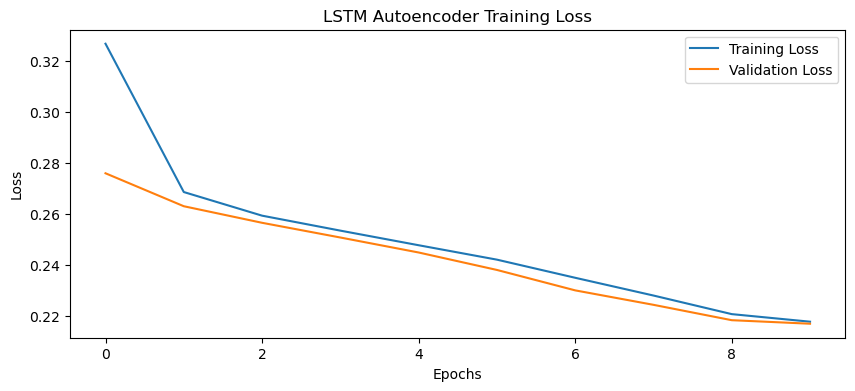

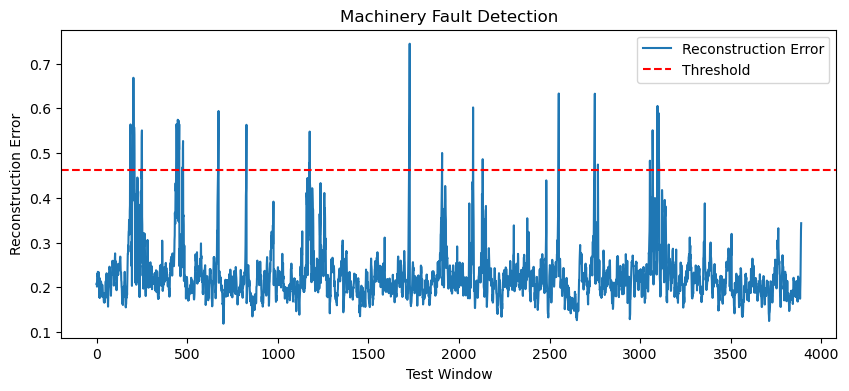

In [1]:
# Assignment 3D: Machinery Fault Detection Using LSTM Autoencoder

# Step 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, LSTM, RepeatVector, TimeDistributed, Dense
)
from tensorflow.keras.optimizers import Adam


# Step 2: Load Dataset

data = pd.read_csv("NASA TurboFan Engine.csv")

print("Dataset Shape:", data.shape)
print("Class Distribution:")
print(data["Fault_Label"].value_counts())


# Step 3: Select Sensor Features

features = [f"sensor{i}" for i in range(1, 22)]

# Sort readings by engine and operating cycle
data = data.sort_values(["unit", "cycle"]).reset_index(drop=True)

# Fill missing sensor values if present
data[features] = data.groupby("unit")[features].transform(
    lambda x: x.ffill().bfill()
)

data[features] = data[features].fillna(data[features].median())


# Step 4: Split Data by Engine ID

engine_ids = data["unit"].unique()

train_ids, test_ids = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

train_data = data[data["unit"].isin(train_ids)].copy()
test_data = data[data["unit"].isin(test_ids)].copy()


# Step 5: Scale Sensor Data

scaler = StandardScaler()

# Fit scaler only on healthy training readings
healthy_train = train_data[train_data["Fault_Label"] == 0]

scaler.fit(healthy_train[features])

train_data.loc[:, features] = scaler.transform(train_data[features])
test_data.loc[:, features] = scaler.transform(test_data[features])


# Step 6: Create Sequential Windows

window_size = 10

def create_windows(df):
    X = []
    y = []

    # Create windows separately for each engine
    for engine_id, group in df.groupby("unit"):

        group = group.sort_values("cycle")

        values = group[features].to_numpy(dtype="float32")
        labels = group["Fault_Label"].to_numpy()

        for i in range(len(values) - window_size + 1):

            X.append(values[i:i + window_size])

            # Faulty if any reading in the window is faulty
            y.append(
                int(np.any(labels[i:i + window_size] == 1))
            )

    return np.array(X), np.array(y)


X_train, y_train = create_windows(train_data)
X_test, y_test = create_windows(test_data)

# Train only on healthy windows
X_train_normal = X_train[y_train == 0]

print("Healthy Training Windows:", X_train_normal.shape)
print("Testing Windows:", X_test.shape)


# Step 7: Build LSTM Autoencoder

model = Sequential([
    Input(shape=(window_size, len(features))),

    LSTM(32, activation="tanh"),

    RepeatVector(window_size),

    LSTM(32, activation="tanh", return_sequences=True),

    TimeDistributed(Dense(len(features)))
])


# Step 8: Compile Model

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()


# Step 9: Train Model

history = model.fit(
    X_train_normal,
    X_train_normal,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    shuffle=True
)


# Step 10: Calculate Training Reconstruction Error

train_predictions = model.predict(
    X_train_normal,
    verbose=0
)

train_error = np.mean(
    np.square(X_train_normal - train_predictions),
    axis=(1, 2)
)


# Step 11: Set Fault Detection Threshold

threshold = np.percentile(train_error, 99)

print("Fault Detection Threshold:", threshold)


# Step 12: Calculate Testing Reconstruction Error

test_predictions = model.predict(X_test, verbose=0)

test_error = np.mean(
    np.square(X_test - test_predictions),
    axis=(1, 2)
)


# Step 13: Detect Faults

y_pred = (test_error > threshold).astype(int)


# Step 14: Evaluate Model

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


# Step 15: Plot Training Loss

plt.figure(figsize=(10, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("LSTM Autoencoder Training Loss")
plt.legend()
plt.show()


# Step 16: Plot Reconstruction Errors

plt.figure(figsize=(10, 4))

plt.plot(test_error, label="Reconstruction Error")

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Test Window")
plt.ylabel("Reconstruction Error")
plt.title("Machinery Fault Detection")
plt.legend()
plt.show()